In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModel
from arabert.preprocess import ArabertPreprocessor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# 1. Charger les splits bruts officiels
train_df = pd.read_csv(r'..\data\splits\train.csv')
val_df = pd.read_csv(r'..\data\splits\val.csv')

# 2. Appliquer le préprocesseur officiel AraBERT
MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"
arabert_prep = ArabertPreprocessor(model_name=MODEL_NAME)

train_texts = [arabert_prep.preprocess(str(t)) for t in train_df["tweet"]]
val_texts = [arabert_prep.preprocess(str(t)) for t in val_df["tweet"]]

y_train = train_df["sarcasm"].astype(bool).astype(int).values
y_val = val_df["sarcasm"].astype(bool).astype(int).values

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
plm_model = AutoModel.from_pretrained(MODEL_NAME).to(device)
# Geler totalement les poids du PLM
plm_model.eval()
for param in plm_model.parameters():
    param.requires_grad = False


Using device: cuda


c:\ghoufrane\Master\M2\llms\TP2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\ghoufrane\Master\M2\llms\TP2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--aubmindlab--bert-base-arabertv02-twitter. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [3]:
def extract_plm_features(texts, tokenizer, model, batch_size=64, max_len=64):
    """
    Extrait pour chaque tweet :
    1. La représentation du token [CLS] (position 0)
    2. La moyenne des tokens pondérée par attention_mask (Mean-Pooling)
    """
    all_cls = []
    all_mean = []
    
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_len,
            return_tensors="pt"
        ).to(device)
        
        with torch.no_grad():
            outputs = model(**encoded)
            # outputs.last_hidden_state a la forme : (batch_size, seq_len, 768)
            hidden_states = outputs.last_hidden_state
            mask = encoded["attention_mask"]  # (batch_size, seq_len)
            
            # 1. Vecteur [CLS]
            cls_rep = hidden_states[:, 0, :]  # (batch_size, 768)
            all_cls.append(cls_rep.cpu().numpy())
            
            # 2. Mean-Pooling pondéré par attention_mask
            mask_expanded = mask.unsqueeze(-1).expand_as(hidden_states).float()
            sum_embeddings = (hidden_states * mask_expanded).sum(dim=1)
            sum_mask = mask_expanded.sum(dim=1).clamp(min=1e-9)
            mean_rep = sum_embeddings / sum_mask  # (batch_size, 768)
            all_mean.append(mean_rep.cpu().numpy())
            
    return np.vstack(all_cls), np.vstack(all_mean)

# Extraction sur Train et Val
X_train_cls, X_train_mean = extract_plm_features(train_texts, tokenizer, plm_model)
X_val_cls, X_val_mean = extract_plm_features(val_texts, tokenizer, plm_model)


In [4]:
def optimize_threshold(y_true, probas):
    """Recherche du seuil maximisant le F1 sarcastique sur val."""
    thresholds = np.linspace(0.01, 0.99, 99)
    best_t, best_f1 = 0.5, 0.0
    for t in thresholds:
        preds = (probas >= t).astype(int)
        score = f1_score(y_true, preds, pos_label=1, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_t = t
    return best_t, best_f1

def evaluate_features(X_tr, y_tr, X_va, y_va, name=""):
    clf = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    clf.fit(X_tr, y_tr)
    
    val_probas = clf.predict_proba(X_va)[:, 1]
    best_t, best_f1 = optimize_threshold(y_va, val_probas)
    val_preds = (val_probas >= best_t).astype(int)
    
    return {
        "Model": f"D1 PLM gelé ({name}) + LogReg",
        "Threshold": round(best_t, 2),
        "val_sarcasm_f1": best_f1,
        "val_pr_auc": average_precision_score(y_va, val_probas),
        "val_macro_f1": f1_score(y_va, val_preds, average="macro"),
        "val_precision": precision_score(y_va, val_preds, pos_label=1, zero_division=0),
        "val_recall": recall_score(y_va, val_preds, pos_label=1, zero_division=0),
        "val_accuracy": accuracy_score(y_va, val_preds),
    }

res_cls = evaluate_features(X_train_cls, y_train, X_val_cls, y_val, name="[CLS]")
res_mean = evaluate_features(X_train_mean, y_train, X_val_mean, y_val, name="Mean-Pooling")
pd.DataFrame([res_cls, res_mean])


,Model,Threshold,val_sarcasm_f1,val_pr_auc,val_macro_f1,val_precision,val_recall,val_accuracy
0,D1 PLM gelé ([CLS]) + LogReg,0.58,0.610365,0.602724,0.753686,0.514563,0.75000,0.837079
1,D1 PLM gelé (Mean-Pooling) + LogReg,0.73,0.617778,0.623799,0.766773,0.584034,0.65566,0.861958


In [5]:
class FrozenPLM_BiLSTMAttention(nn.Module):
    """
    Encodeur AraBERT gelé + Tête BiLSTM et pooling attentionnel de C2.
    """
    def __init__(self, plm, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.plm = plm
        # Geler l'encodeur
        for p in self.plm.parameters():
            p.requires_grad = False
            
        plm_dim = plm.config.hidden_size  # 768
        
        # Tête BiLSTM
        self.lstm = nn.LSTM(
            input_size=plm_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )
        
        # Attention additive (identique à C2)
        self.W = nn.Linear(hidden_dim * 2, hidden_dim * 2, bias=False)
        self.v = nn.Linear(hidden_dim * 2, 1, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, input_ids, attention_mask, return_attention=False):
        # Passage dans le PLM gelé sans gradient
        with torch.no_grad():
            plm_out = self.plm(input_ids=input_ids, attention_mask=attention_mask)
            states = plm_out.last_hidden_state  # (batch, seq_len, 768)
            
        states = self.dropout(states)
        lstm_out, _ = self.lstm(states)  # (batch, seq_len, 256)
        
        # Calcul des poids d'attention avec masquage du padding
        scores = self.v(torch.tanh(self.W(lstm_out))).squeeze(-1)  # (batch, seq_len)
        scores = scores.masked_fill(~attention_mask.bool(), -1e9)
        alpha = torch.softmax(scores, dim=-1)  # (batch, seq_len)
        
        # Vecteur de contexte
        context = torch.bmm(alpha.unsqueeze(1), lstm_out).squeeze(1)  # (batch, 256)
        logits = self.fc(self.dropout(context))
        
        if return_attention:
            return logits, alpha
        return logits


In [8]:
class TextTokenDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=64):
        self.encodings = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=max_len,
            return_tensors="pt"
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx]
        }

train_ds = TextTokenDataset(train_texts, y_train, tokenizer)
val_ds = TextTokenDataset(val_texts, y_val, tokenizer)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

# Boucle d'entraînement
model_d2 = FrozenPLM_BiLSTMAttention(plm_model).to(device)

# Poids de perte pondérée pour le déséquilibre
# Forcer le dtype en float32
weight_sarc = float((len(y_train) - sum(y_train)) / sum(y_train))
weights = torch.tensor([1.0, weight_sarc], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.AdamW(model_d2.parameters(), lr=1e-3, weight_decay=1e-4)

best_val_f1 = 0.0
best_state = None
patience = 2
patience_counter = 0

for epoch in range(1, 9):
    model_d2.train()
    # S'assurer que le PLM reste en eval
    plm_model.eval()
    total_loss = 0.0
    
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        # .long() et .view(-1) pour garantir le bon format 1D
        targets = batch["label"].to(device).long().view(-1)

        optimizer.zero_grad()
        logits = model_d2(input_ids, mask)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Évaluation sur val
    model_d2.eval()
    val_preds, val_probas, val_targets = [], [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            logits = model_d2(input_ids, mask)
            probs = torch.softmax(logits, dim=-1)[:, 1]
            
            val_probas.extend(probs.cpu().numpy())
            val_targets.extend(batch["label"].numpy())
            
    val_targets = np.array(val_targets)
    val_probas = np.array(val_probas)
    
    # Seuil sur val
    best_t, current_f1 = optimize_threshold(val_targets, val_probas)
    print(f"Epoch {epoch:02d} | Train Loss: {total_loss/len(train_loader):.4f} | Val F1 (sarcasm): {current_f1:.4f} (seuil {best_t:.2f})")
    
    if current_f1 > best_val_f1:
        best_val_f1 = current_f1
        best_state = model_d2.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping déclenché à l'époque {epoch}")
            break

model_d2.load_state_dict(best_state)


Epoch 01 | Train Loss: 0.4473 | Val F1 (sarcasm): 0.6590 (seuil 0.75)
Epoch 02 | Train Loss: 0.3692 | Val F1 (sarcasm): 0.6870 (seuil 0.53)
Epoch 03 | Train Loss: 0.3297 | Val F1 (sarcasm): 0.6535 (seuil 0.69)
Epoch 04 | Train Loss: 0.2983 | Val F1 (sarcasm): 0.6779 (seuil 0.70)
Early stopping déclenché à l'époque 4


<All keys matched successfully>

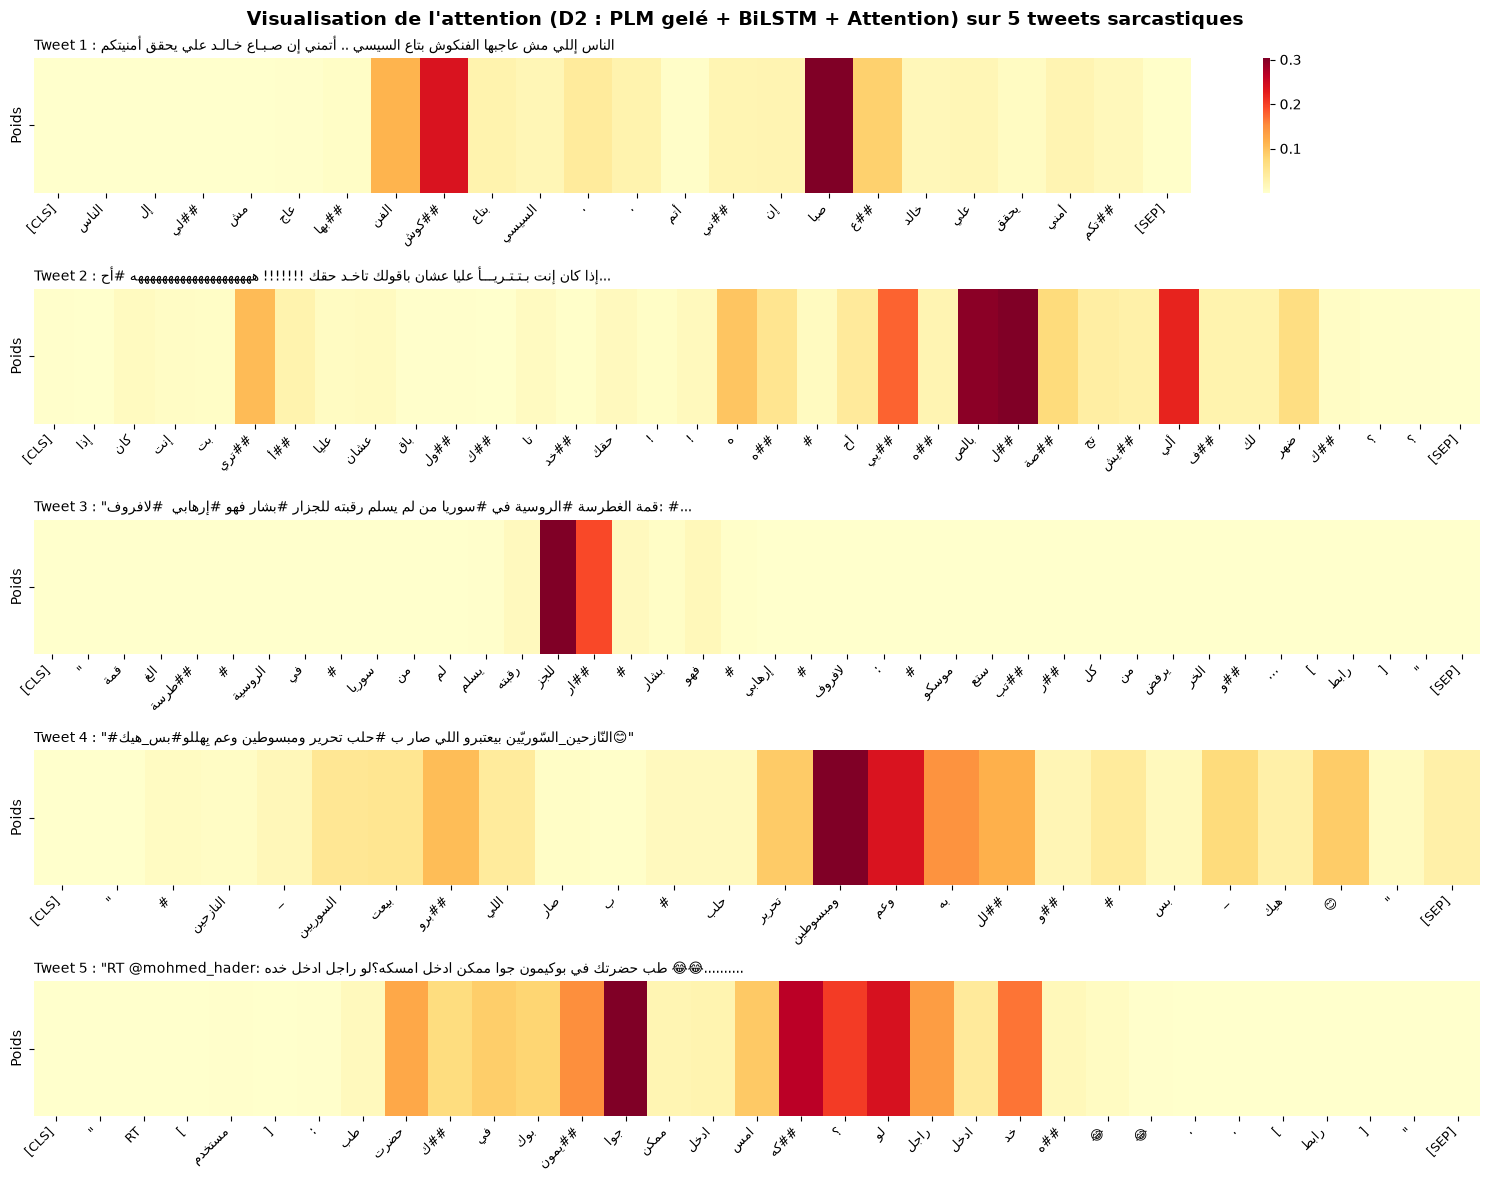

In [14]:
# 1. Sélectionner 5 tweets sarcastiques bien prédits (vrais positifs)
model_d2.eval()
sarcastic_indices = np.where(y_val == 1)[0]
selected_indices = []

for idx in sarcastic_indices:
    raw_text = val_df.iloc[idx]["tweet"]
    prep_text = val_texts[idx]
    encoded = tokenizer([prep_text], return_tensors="pt", padding=True, truncation=True).to(device)
    
    with torch.no_grad():
        logits, alpha = model_d2(encoded["input_ids"], encoded["attention_mask"], return_attention=True)
        prob = torch.softmax(logits, dim=-1)[0, 1].item()
        
    if prob > 0.5:  # Seuil de confiance
        selected_indices.append(idx)
        
    if len(selected_indices) == 5:
        break

# 2. Visualiser les heatmaps de l'attention
fig, axes = plt.subplots(5, 1, figsize=(15, 12))
fig.suptitle("Visualisation de l'attention (D2 : PLM gelé + BiLSTM + Attention) sur 5 tweets sarcastiques", fontsize=14, fontweight="bold")

for i, idx in enumerate(selected_indices):
    raw_text = val_df.iloc[idx]["tweet"]
    prep_text = val_texts[idx]
    encoded = tokenizer([prep_text], return_tensors="pt", padding=True, truncation=True).to(device)
    
    with torch.no_grad():
        logits, alpha = model_d2(encoded["input_ids"], encoded["attention_mask"], return_attention=True)
        
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    valid_len = encoded["attention_mask"][0].sum().item()
    
    valid_tokens = tokens[:valid_len]
    valid_weights = alpha[0].cpu().numpy()[:valid_len].reshape(1, -1)
    
    ax = axes[i]
    sns.heatmap(
        valid_weights,
        cmap="YlOrRd",
        cbar=(i == 0),
        ax=ax,
        yticklabels=["Poids"],
        xticklabels=valid_tokens
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    short_title = raw_text[:85] + "..." if len(raw_text) > 85 else raw_text
    ax.set_title(f"Tweet {i+1} : {short_title}", fontsize=10, loc="left")

plt.tight_layout()
plt.savefig(r"..\results\attention_d2_5tweets.png", dpi=300, bbox_inches="tight")
plt.show()
